# 02 · Data cleaning and exclusion ledger

**Goal.** Turn the integrated raw data (steps 01-02) into two analysis-ready sets:

1. **PDE4 activity measurements** → `activities_clean` (one row per measurement, with pIC50/pKi) and `activity_potency` (median per molecule and target).
2. **Inhaled vs oral drugs** → `inhalation_dataset` (one row per molecule, exclusive groups).

**Ground rules.**
- Raw tables are never modified: everything that is cleaned goes into new tables.
- Rules are applied in order; each rule only sees the rows left by the previous ones, so **every excluded row has exactly one reason**.
- The **exclusion ledger** (`cleaning_log` + `cleaning_exclusions`) records how many rows each rule removes, why, and which ones.

The logic lives in `src/cleaning.py` (reusable and testable); this notebook runs it step by step and shows the evidence.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import cleaning

con = sqlite3.connect(ROOT / "data" / "processed" / "pharma_inhalation.sqlite")
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "axes.axisbelow": True})
COLORS = {"inhaled": "#2a78d6", "oral": "#eb6834"}
LOG_COLUMNS = ["rule_id", "kind", "rule", "rows_before", "rows_removed", "rows_after", "rows_flagged"]

pd.read_sql_query("SELECT key, value FROM dataset_info WHERE key NOT LIKE 'sha256:%' AND key NOT LIKE 'retrieved_at:%'", con)

,key,value
0,chembl_release,ChEMBL_37
1,chembl_release_date,2026-05-01
2,openfda_last_updated,2026-10-20
3,built_at,2026-10-21T12:01:43+00:00


## Part A · PDE4 activity measurements

### A.1 Before cleaning: what are the problems?
A potency measurement is reliable only if it is a point value (`=`), in a concentration unit, with no curator flags. We count the cases with SQL directly on the raw tables.

In [2]:
pd.read_sql_query("""
    SELECT COALESCE(standard_relation, '(empty)') AS relation, COUNT(*) AS measurements
    FROM activities
    GROUP BY 1
    ORDER BY measurements DESC
""", con)

,relation,measurements
0,=,8979
1,<,1442
2,>,1213
3,(empty),314
4,>=,5
5,<=,1


The units published in papers are heterogeneous (nM, µM, mM, even `10'3nM`). ChEMBL converts them to nM in the `standard_units` column, which is why the program uses the standardised values and not the published ones.

In [3]:
pd.read_sql_query("""
    SELECT COALESCE(published_units, '(empty)') AS published_units,
           COALESCE(standard_units, '(empty)')  AS standard_units,
           COUNT(*) AS measurements
    FROM activities
    GROUP BY 1, 2
    ORDER BY measurements DESC
""", con)

,published_units,standard_units,measurements
0,nM,nM,7551
1,uM,nM,3304
2,(empty),nM,677
3,(empty),(empty),292
4,mM,nM,86
5,10'3nM,nM,12
6,%,%,10
7,pM,nM,10
8,M,nM,7
9,10'-3microM,nM,2


### A.2 Applying the rules
For each clean measurement the potency becomes a logarithm: **pX = 9 − log10(value in nM)**. An IC50 of 10 nM corresponds to pIC50 = 8; each additional unit means 10 times more potent. The log scale makes values from picomolar to millimolar comparable and allows the use of the median.

In [4]:
raw_activities = cleaning.load_activities(con)
activities, potency, ledger_a = cleaning.clean_activities(raw_activities)
log_a = ledger_a.log_frame()
log_a[LOG_COLUMNS]

,rule_id,kind,rule,rows_before,rows_removed,rows_after,rows_flagged
0,A0,input,IC50 and Ki measurements on human PDE4 downloaded from ChEMBL,11954,0,11954,0
1,A1,exclude,Measurements flagged by ChEMBL curators,11954,259,11695,0
2,A2,exclude,Relation other than '=',11695,2892,8803,0
3,A3,exclude,Standard unit other than nM,8803,10,8793,0
4,A4,exclude,Missing or non-positive value,8793,0,8793,0
5,A5,exclude,pIC50/pKi outside 3-12,8793,0,8793,0
6,A6,check,Comparison with the pChEMBL value calculated by ChEMBL,8793,0,8793,0
7,A7,aggregate,Median of repeated measurements,8793,0,6887,0
8,A8,check,Replicates more than 1 log unit apart,6887,0,6887,208


In [5]:
log_a.loc[log_a["kind"] != "input", ["rule_id", "rule", "reason"]]

,rule_id,rule,reason
1,A1,Measurements flagged by ChEMBL curators,"The data_validity_comment field marks a suspect value (units, transcription, out of range)."
2,A2,Relation other than '=',"Censored values (<, >) only say that potency is above or below a threshold: they are not a point estimate."
3,A3,Standard unit other than nM,Percentages or missing units cannot be converted into a concentration.
4,A4,Missing or non-positive value,The logarithm needs a numeric value greater than zero.
5,A5,pIC50/pKi outside 3-12,A potency weaker than 1 mM or stronger than 1 pM is almost always a unit error.
6,A6,Comparison with the pChEMBL value calculated by ChEMBL,Flags measurements where the calculated pX differs from pChEMBL by more than 0.05.
7,A7,Median of repeated measurements,One row per molecule × target × measurement type; the median is robust to outliers.
8,A8,Replicates more than 1 log unit apart,Pairs whose measurements differ more than 10-fold: kept but flagged.


Check **A6** compares the pX calculated here with the `pchembl_value` that ChEMBL calculates independently: if the two routes give the same number, the conversion is correct. Check **A8** flags molecule-target pairs whose measurements differ more than 10-fold: they stay in the data, but should be reviewed before drawing conclusions about that molecule.

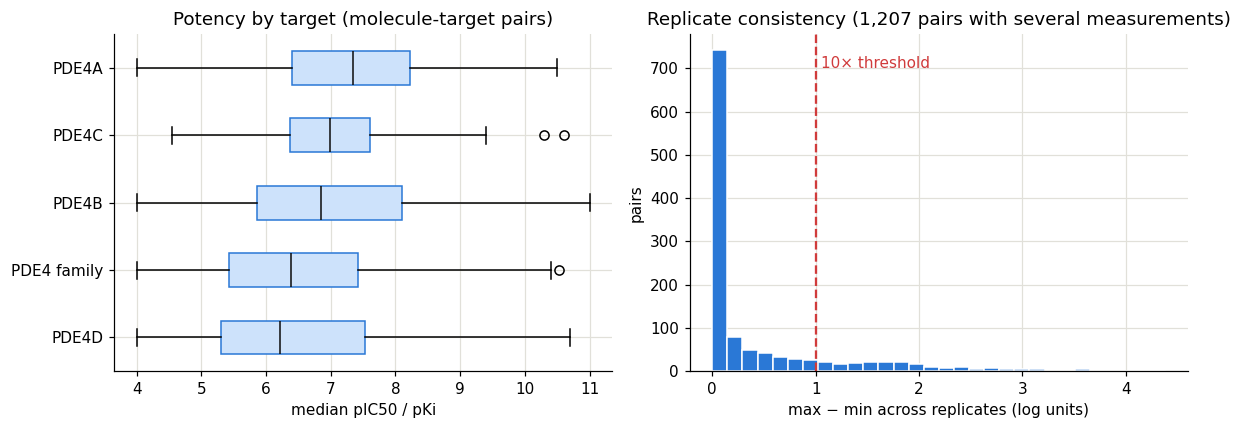

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = potency.groupby("target_name")["p_median"].median().sort_values().index
axes[0].boxplot([potency.loc[potency.target_name == t, "p_median"] for t in order],
                tick_labels=order, vert=False, patch_artist=True,
                boxprops={"facecolor": "#cde2fb", "color": "#2a78d6"}, medianprops={"color": "#0b0b0b"})
axes[0].set_xlabel("median pIC50 / pKi")
axes[0].set_title("Potency by target (molecule-target pairs)")

replicated = potency[potency.n_measurements > 1]
axes[1].hist(replicated["p_range"], bins=30, color="#2a78d6", edgecolor="white")
axes[1].axvline(cleaning.INCONSISTENT_RANGE, color="#d03b3b", linestyle="--", linewidth=1.5)
axes[1].text(cleaning.INCONSISTENT_RANGE + 0.05, axes[1].get_ylim()[1] * 0.9, "10× threshold", color="#d03b3b")
axes[1].set_xlabel("max − min across replicates (log units)")
axes[1].set_ylabel("pairs")
axes[1].set_title(f"Replicate consistency ({len(replicated):,} pairs with several measurements)")
fig.tight_layout()
fig.savefig(FIG / "activities_potency.png", bbox_inches="tight")
plt.show()

## Part B · Inhaled vs oral drugs

### B.1 The "route of administration" field is not uniform
The same concept is written in different ways: a single route, several routes separated by commas, upper and lower case. Before cleaning, only the exact text `INHALATION` was recognised.

In [7]:
pd.read_sql_query("""
    SELECT route, COUNT(*) AS products
    FROM fda_products
    WHERE UPPER(route) LIKE '%INHAL%'
    GROUP BY route
    ORDER BY products DESC
""", con)

,route,products
0,INHALATION,609
1,"INHALATION, ORAL",21
2,"Inhalation, Oral",2
3,"INHALATION, INTRAVENOUS",2
4,"INHALATION, INJECTION",1


### B.2 Applying the rules
Three transformations prepare the data (M0a-M0c), then six rules exclude the molecules that do not answer the question. The logic of exclusions M5 and M6 is symmetrical:
- an inhaled drug acting on the **nervous system** is inhaled to reach the blood (anaesthetics, loxapine, levodopa): it does not represent a drug meant to stay in the lung;
- an oral drug acting **only in the gut** is designed not to be absorbed: it does not represent a systemic oral drug.

In [8]:
dataset, routes, ledger_m = cleaning.clean_molecules(con)
log_m = ledger_m.log_frame()
log_m[LOG_COLUMNS]

,rule_id,kind,rule,rows_before,rows_removed,rows_after,rows_flagged
0,M0,input,Parent molecules with at least one oral or inhaled FDA product,1305,0,1305,0
1,M0a,transform,Routes of administration split and upper-cased,1305,0,1305,0
2,M0b,transform,ATC codes inherited from salts,1305,0,1305,0
3,M0c,transform,Exclusive groups: inhaled takes precedence over oral,1305,0,1305,15
4,M1,exclude,Not a small molecule,1305,37,1268,0
5,M2,exclude,Core chemical properties missing,1268,63,1205,0
6,M3,exclude,Medical gases,1205,10,1195,0
7,M4,exclude,Diagnostics only,1195,12,1183,0
8,M5,exclude,Inhaled drugs acting systemically on the nervous system,1183,9,1174,0
9,M6,exclude,Oral drugs acting locally in the gut,1174,20,1154,0


In [9]:
log_m.loc[log_m["kind"].isin(["transform", "exclude"]), ["rule_id", "rule", "reason"]]

,rule_id,rule,reason
1,M0a,Routes of administration split and upper-cased,"""INHALATION, ORAL"" and ""Inhalation, Oral"" count for both routes: inhaled molecules go from 65 (exact text ..."
2,M0b,ATC codes inherited from salts,Many ATC codes are stored on the salt (e.g. tiotropium bromide): they are assigned to the parent molecule.
3,M0c,Exclusive groups: inhaled takes precedence over oral,A molecule with inhaled products goes into the inhaled group (also_oral = 1 if it also exists as an oral p...
4,M1,Not a small molecule,Proteins and mixtures have no comparable calculated properties.
5,M2,Core chemical properties missing,"All are required: mw_freebase, alogp, psa, hbd, hba. They are missing for ions and noble gases."
6,M3,Medical gases,"Molecular weight below 100 Da or ATC V03AN (oxygen, nitrogen, nitrous oxide...): not designed drugs."
7,M4,Diagnostics only,"All ATC codes are V04/V08/V09 (challenge tests, contrast agents, radiopharmaceuticals)."
8,M5,Inhaled drugs acting systemically on the nervous system,"First-level ATC N (volatile anaesthetics, loxapine, levodopa): they are inhaled to reach the blood, the op..."
9,M6,Oral drugs acting locally in the gut,"All ATC codes are A06/A07 (laxatives, intestinal anti-infectives and anti-inflammatories): they are design..."


### B.3 Which inhaled molecules were excluded, and why
This is the table to show when someone asks "why does your inhaled group have 46 molecules and not 66?".

In [10]:
names = pd.read_sql_query("SELECT chembl_id AS record_id, pref_name FROM molecules", con)
inhaled_ids = set(routes.loc[routes.route == "INHALATION", "chembl_id"])
excluded = ledger_m.exclusions_frame()
(excluded[excluded.record_id.isin(inhaled_ids)]
    .merge(names, on="record_id")
    .merge(log_m[["rule_id", "rule"]], on="rule_id")
    .groupby(["rule_id", "rule"])["pref_name"].agg(lambda s: ", ".join(sorted(s)))
    .reset_index(name="excluded inhaled molecules"))

,rule_id,rule,excluded inhaled molecules
0,M1,Not a small molecule,"INSULIN HUMAN, TECHNETIUM TC-99M LABELED CARBON"
1,M2,Core chemical properties missing,"HELIUM, KRYPTON, SODIUM CHLORIDE, XENON"
2,M3,Medical gases,"NITRIC OXIDE, NITROGEN, NITROUS OXIDE, OXYGEN"
3,M4,Diagnostics only,METHACHOLINE
4,M5,Inhaled drugs acting systemically on the nervous system,"DESFLURANE, ENFLURANE, ERGOTAMINE, HALOTHANE, ISOFLURANE, LEVODOPA, LOXAPINE, METHOXYFLURANE, SEVOFLURANE"


### B.4 Check: the reference inhaled drugs must be present
If a rule removed them, the rule would be wrong. The notebook stops with an error if one of them is missing or ends up in the wrong group.

In [11]:
reference = ["ALBUTEROL", "BUDESONIDE", "FLUTICASONE PROPIONATE", "FORMOTEROL",
             "IPRATROPIUM", "SALMETEROL", "TIOTROPIUM"]
check = dataset.set_index("pref_name").reindex(reference)[["route_group", "also_oral", "mw_freebase", "psa", "alogp", "hbd"]]
assert check["route_group"].eq("inhaled").all(), "A reference inhaled drug was excluded"
check

,route_group,also_oral,mw_freebase,psa,alogp,hbd
pref_name,,,,,,
ALBUTEROL,inhaled,1,239.31,72.72,1.31,4.0
BUDESONIDE,inhaled,1,430.54,93.06,2.72,2.0
FLUTICASONE PROPIONATE,inhaled,0,500.58,80.67,4.43,1.0
FORMOTEROL,inhaled,0,344.41,90.82,2.22,4.0
IPRATROPIUM,inhaled,0,332.46,46.53,2.85,1.0
SALMETEROL,inhaled,0,415.57,81.95,4.11,4.0
TIOTROPIUM,inhaled,0,392.52,59.06,2.35,1.0


### B.5 First look at the two groups
Descriptive statistics only: the comparison with tests and effect sizes is the job of notebook 03.

In [12]:
summary = dataset.groupby("route_group")[["mw_freebase", "alogp", "psa", "hbd", "hba", "rtb"]].median().round(1)
summary.insert(0, "molecules", dataset.groupby("route_group").size())
summary

,molecules,mw_freebase,alogp,psa,hbd,hba,rtb
route_group,,,,,,,
inhaled,46,391.5,2.3,90.8,3.5,6.0,5.0
oral,1108,349.4,2.9,75.7,2.0,4.0,5.0


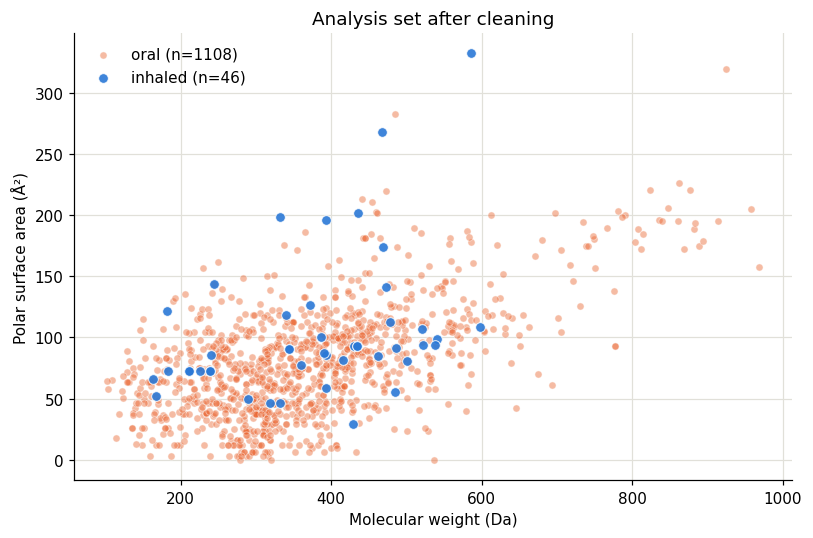

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for group in ["oral", "inhaled"]:
    d = dataset[dataset.route_group == group]
    ax.scatter(d.mw_freebase, d.psa, s=22 if group == "oral" else 40, alpha=0.45 if group == "oral" else 0.9,
               color=COLORS[group], edgecolor="white", linewidth=0.6, label=f"{group} (n={len(d)})")
ax.set_xlabel("Molecular weight (Da)")
ax.set_ylabel("Polar surface area (Å²)")
ax.set_title("Analysis set after cleaning")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "inhaled_vs_oral_after_cleaning.png", bbox_inches="tight")
plt.show()

## Exclusion flow
Like a CONSORT diagram in clinical trials: from the starting records to the analysed set, with the weight of each rule.

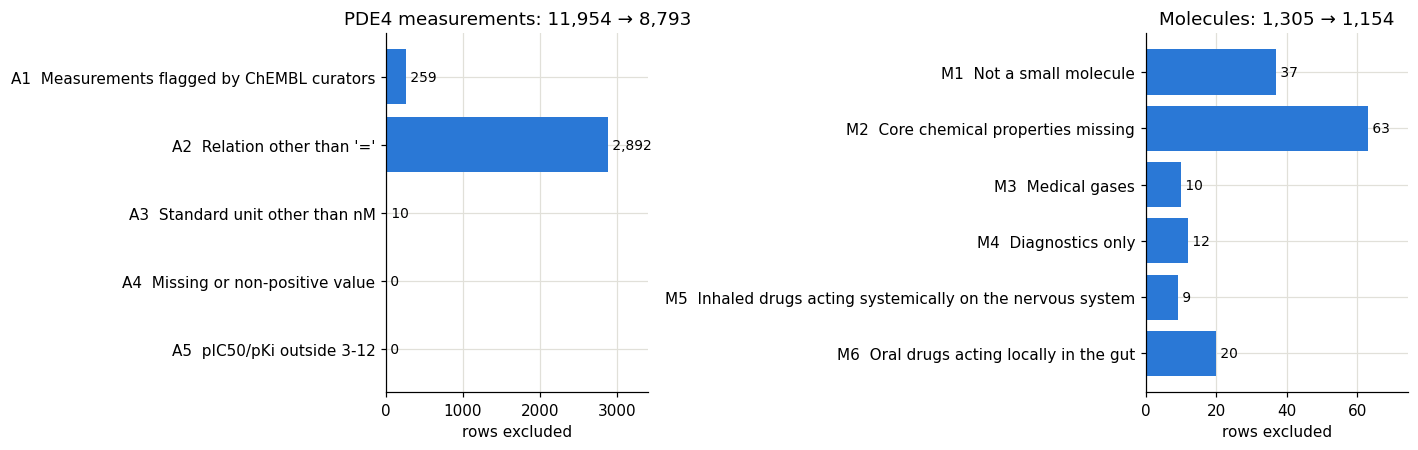

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, log, title in [(axes[0], log_a, "PDE4 measurements"), (axes[1], log_m, "Molecules")]:
    steps = log[log.kind == "exclude"]
    labels = steps.rule_id + "  " + steps.rule.str.slice(0, 60)
    ax.barh(labels[::-1], steps.rows_removed[::-1], color="#2a78d6")
    for y, v in enumerate(steps.rows_removed[::-1]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9)
    start, end = log.iloc[0].rows_after, steps.iloc[-1].rows_after
    ax.set_title(f"{title}: {start:,} → {end:,}")
    ax.set_xlabel("rows excluded")
    ax.margins(x=0.18)
fig.tight_layout()
fig.savefig(FIG / "exclusion_flow.png", bbox_inches="tight")
plt.show()

## Saving and integrity checks
The clean tables and the ledger are written to the database (the SQL app can query them too), to `reports/cleaning_log.csv` and to the database copy used by the app.

In [15]:
log = cleaning.save_outputs(con, [ledger_a, ledger_m], {
    "activities_clean": activities, "activity_potency": potency,
    "molecule_routes_clean": routes, "inhalation_dataset": dataset,
})

# Integrity: what was excluded + what was kept = what came in.
counts = dict(con.execute("""
    SELECT 'activities_clean', COUNT(*) FROM activities_clean UNION ALL
    SELECT 'activity_potency', COUNT(*) FROM activity_potency UNION ALL
    SELECT 'inhalation_dataset', COUNT(*) FROM inhalation_dataset UNION ALL
    SELECT 'excl_activities', COUNT(*) FROM cleaning_exclusions WHERE dataset = 'activities' UNION ALL
    SELECT 'excl_molecules', COUNT(*) FROM cleaning_exclusions WHERE dataset = 'molecules'
""").fetchall())
assert counts["activities_clean"] + counts["excl_activities"] == len(raw_activities)
assert counts["inhalation_dataset"] + counts["excl_molecules"] == log_m.iloc[0].rows_before
assert counts["excl_activities"] == log_a.rows_removed.sum() and counts["excl_molecules"] == log_m.rows_removed.sum()
pd.Series(counts, name="rows")

activities_clean      8793
activity_potency      6887
inhalation_dataset    1154
excl_activities       3161
excl_molecules         151
Name: rows, dtype: int64

## Summary
- Every exclusion has a rule, a written reason and a list of the records involved, which can be queried with SQL (`cleaning_log`, `cleaning_exclusions`).
- The integrity checks verify that excluded records + kept records = starting records.
- **Next step (notebook 03):** statistical comparison of inhaled vs oral drugs (Mann-Whitney, effect sizes, bootstrap intervals) and a sensitivity analysis without the `also_oral` molecules.